# **Notebook 3: Feature Selection — Revised, separated LR / RF / ANN**

This notebook keeps the original three model-specific pipelines in distinct sections:
1. **Logistic Regression:** LASSO `C` (inner 5-fold AUC), 100 bootstrap stability selections (>=60%).
2. **Random Forest:** 30 bootstraps, 10-permutation-repeat AUC importance, >=60% positive resamples **and** positive mean importance.
3. **Artificial Neural Network:** Same rule, balanced bootstrap and fold-training-only scaler.

**Two kinds of feature selection are run for each model:** (A) the **full 530-row training set**, for the final fit; (B) five **independent outer CV training folds** (about 424 rows each) to be used only in NB4 validation. NO test outcomes are used to select features. The source NB1 train/test files and your existing NB3 exports are preserved in a new output directory.

### **Import libraries and set paths**

In [2]:
from pathlib import Path
import os, json, time, warnings, shutil, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.utils import resample
from sklearn.exceptions import ConvergenceWarning
from tqdm.auto import tqdm

RANDOM_STATE = 42
N_FOLDS = 5
PI_THR = 0.60
C_VALUES = [0.05, 0.06, 0.07, 0.1, 0.3, 0.5, 0.6, 0.7]
N_BOOTSTRAPS_LR = 100
N_BOOTSTRAPS_RF = 30
N_BOOTSTRAPS_ANN = 30
N_REPEATS_RF = 10
N_REPEATS_ANN = 10
LASSO_MAX_ITER = 10000
ANN_MAX_ITER = 2000

PROJECT_ROOT = Path.cwd()

SOURCE_DIR = PROJECT_ROOT / "NB_OUTS1"
OUT_DIR = PROJECT_ROOT / "NB_OUTS1_TRAINONLY"

assert (SOURCE_DIR / "NB1_train_LR.csv").exists(), \
    "NB1 outputs not found. Run NB1 first."

OUT_DIR.mkdir(parents=True, exist_ok=True)

FOLDS_DIR = OUT_DIR / "folds"
FOLDS_DIR.mkdir(parents=True, exist_ok=True)
FOLDS_DIR.mkdir(parents=True, exist_ok=True)

print('Reading NB1 outputs from:', SOURCE_DIR)
print('Writing NEW files to     :', OUT_DIR)
print('FULL research settings: 100 LR, 30 RF, 30 ANN bootstraps, five outer folds.')
print('CAUTION: this runs feature selection six times and may be computationally intensive.')

Reading NB1 outputs from: /home/kathleen/THESIS1/NB_OUTS1
Writing NEW files to     : /home/kathleen/THESIS1/NB_OUTS1_TRAINONLY
FULL research settings: 100 LR, 30 RF, 30 ANN bootstraps, five outer folds.
CAUTION: this runs feature selection six times and may be computationally intensive.


### **Load and check the pre-split NB1 data**

In [3]:
lr_train = pd.read_csv(SOURCE_DIR / 'NB1_train_LR.csv', index_col='orig_index')
lr_test = pd.read_csv(SOURCE_DIR / 'NB1_test_LR.csv', index_col='orig_index')
rf_train = pd.read_csv(SOURCE_DIR / 'NB1_train_RF_ANN.csv', index_col='orig_index')
rf_test = pd.read_csv(SOURCE_DIR / 'NB1_test_RF_ANN.csv', index_col='orig_index')

assert lr_train.index.is_unique and lr_test.index.is_unique
assert lr_train.index.equals(rf_train.index) and lr_test.index.equals(rf_test.index)
assert len(set(lr_train.index).intersection(set(lr_test.index))) == 0
assert lr_train['depressed_flag'].equals(rf_train['depressed_flag'])
assert lr_test['depressed_flag'].equals(rf_test['depressed_flag'])
assert 'cesd' not in rf_train.columns or 'cesd' not in rf_train.drop(columns=['cesd'],errors='ignore').columns

y_train = lr_train['depressed_flag'].astype(int)
y_test = lr_test['depressed_flag'].astype(int)
X_lr = lr_train.drop(columns=['depressed_flag', 'cesd'], errors='ignore').copy()
X_rfann = rf_train.drop(columns=['depressed_flag', 'cesd'], errors='ignore').copy()
X_lr_test = lr_test.drop(columns=['depressed_flag','cesd'],errors='ignore').copy()
X_rfann_test = rf_test.drop(columns=['depressed_flag','cesd'],errors='ignore').copy()

for label, frame in [('LR train',X_lr),('LR test',X_lr_test),('RF/ANN train',X_rfann),('RF/ANN test',X_rfann_test)]:
    assert not frame.isna().any().any(), f'{label} has NaN'
    assert all(pd.api.types.is_numeric_dtype(frame[c]) for c in frame.columns), f'{label} has nonnumeric columns'
assert len(X_lr) == 530 and len(X_lr_test) == 133, 'Unexpected sample size: check NB1 files.'
assert int(y_train.sum()) == 78 and int(y_test.sum()) == 19, 'Unexpected HDS count: check NB1.'
print(f'LR candidates: {X_lr.shape[1]} | RF/ANN candidates: {X_rfann.shape[1]}')
print(f'Train {len(y_train)}: HDS={int(y_train.sum())}, MNDS={int((y_train==0).sum())}')
print(f'Test  {len(y_test)}: HDS={int(y_test.sum())}, MNDS={int((y_test==0).sum())}')
print('The held-out test outcomes are used only for integrity checks, never for feature selection.')

level_map = SOURCE_DIR / 'NB1_RF_ANN_level_order.csv'
if level_map.exists():
    shutil.copy2(level_map, OUT_DIR / level_map.name)
    print('Copied NB1 categorical level labels for later NB6 interpretation.')

PRELEARN_FILE = SOURCE_DIR / 'NB1_prelearn_cleaned_NCR.pkl'
if not PRELEARN_FILE.exists():
    raise FileNotFoundError(
        'Missing NB1_prelearn_cleaned_NCR.pkl. Rerun the MINIMAL-TRIAL NB1 '
        'before this NB3 to create it.'
    )
prelearn = pd.read_pickle(PRELEARN_FILE)
prelearn_df = prelearn['data'].copy()
prelearn_labels = prelearn['spss_value_labels']
assert set(prelearn_df.index) == set(lr_train.index).union(lr_test.index)
assert set(prelearn['train_idx']) == set(lr_train.index)
assert set(prelearn['test_idx']) == set(lr_test.index)
print('Loaded deterministic pre-encoding checkpoint for fold-specific refitting.')

LR candidates: 518 | RF/ANN candidates: 154
Train 530: HDS=78, MNDS=452
Test  133: HDS=19, MNDS=114
The held-out test outcomes are used only for integrity checks, never for feature selection.
Copied NB1 categorical level labels for later NB6 interpretation.
Loaded deterministic pre-encoding checkpoint for fold-specific refitting.


### **Shared selection functions (called separately by each model)**

A selector receives **only its supplied training rows**. Any scaling, bootstrap resampling, permutation holdout, and inner regularization search are restricted to those rows. The outer CV validation rows are not used.

In [4]:
def choose_lasso_c(X, y, seed):
    """Inner CV chooses C using only the current (full or outer-fold) training set."""
    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    rows = []
    for c in C_VALUES:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('lr', LogisticRegression(C=c, l1_ratio=1.0, solver='saga',
                                       class_weight='balanced', max_iter=LASSO_MAX_ITER,
                                       random_state=seed))
        ])
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            scores = cross_val_score(pipe, X, y, cv=inner_cv, scoring='roc_auc', n_jobs=1)
        rows.append({'C':float(c),'mean_auc':float(np.mean(scores)),'std_auc':float(np.std(scores))})
    cv_table = pd.DataFrame(rows)
    chosen = cv_table.sort_values(['mean_auc','C'], ascending=[False,True]).iloc[0]
    return float(chosen['C']), cv_table


def lasso_stability(X, y, selected_c, seed):
    """L1 stability selection; no validation rows passed in."""
    coefs = []
    for b in range(N_BOOTSTRAPS_LR):
        Xb, yb = resample(X, y, replace=True, n_samples=len(X), random_state=seed+b)
        scaler = StandardScaler()
        Xbs = scaler.fit_transform(Xb)
        model = LogisticRegression(C=selected_c, l1_ratio=1.0, solver='saga',
                                   class_weight='balanced', max_iter=LASSO_MAX_ITER,
                                   random_state=seed+b)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            model.fit(Xbs, yb)
        coefs.append(model.coef_[0].copy())
    coef_arr = np.asarray(coefs)
    table = pd.DataFrame({
        'feature':list(X.columns),
        'coef_mean':coef_arr.mean(axis=0),
        'coef_std':coef_arr.std(axis=0),
        'selection_frequency':(coef_arr != 0).mean(axis=0)
    }).sort_values(['selection_frequency','feature'], ascending=[False,True])
    table['selected'] = table['selection_frequency'] >= PI_THR
    features = table.loc[table['selected'],'feature'].tolist()
    if not features:
        raise RuntimeError('No LR features selected; inspect C and feature-selection stability.')
    return features, table

def balanced_bootstrap(X, y, seed):
    """Balance the bootstrap sample, without looking at validation labels."""
    rng = np.random.RandomState(seed)
    ix0 = np.flatnonzero(np.asarray(y)==0)
    ix1 = np.flatnonzero(np.asarray(y)==1)
    if not len(ix0) or not len(ix1):
        raise ValueError('Both classes must be present in each training fold.')
    locs = np.r_[rng.choice(ix0, len(ix0), True), rng.choice(ix1, len(ix0), True)]
    rng.shuffle(locs)
    return X.iloc[locs], y.iloc[locs]

def permutation_stability(X, y, algorithm, seed):
    """RF or ANN selection using an INTERNAL train/permutation-validation split."""
    Xpool, Xperm, ypool, yperm = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed)
    n_boot = N_BOOTSTRAPS_RF if algorithm=='RF' else N_BOOTSTRAPS_ANN
    n_repeat = N_REPEATS_RF if algorithm=='RF' else N_REPEATS_ANN
    imp_rows = []
    for b in range(n_boot):
        if algorithm == 'RF':
            Xb, yb = resample(Xpool, ypool, replace=True, n_samples=len(Xpool),random_state=seed+b)
            m = RandomForestClassifier(n_estimators=200,max_depth=8,class_weight='balanced',
                                       random_state=seed+b,n_jobs=-1)
            m.fit(Xb, yb)
            result = permutation_importance(m, Xperm, yperm, n_repeats=n_repeat,
                                            scoring='roc_auc', random_state=seed+b,n_jobs=1)
        elif algorithm == 'ANN':
            Xb, yb = balanced_bootstrap(Xpool, ypool, seed+b)
            scaler = StandardScaler().fit(Xb)
            m = MLPClassifier(hidden_layer_sizes=(32,16), activation='relu',solver='adam',
                              alpha=0.01,max_iter=ANN_MAX_ITER,random_state=seed+b)
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', ConvergenceWarning)
                m.fit(scaler.transform(Xb), yb)
            result = permutation_importance(m, scaler.transform(Xperm),yperm,
                                            n_repeats=n_repeat,scoring='roc_auc',
                                            random_state=seed+b,n_jobs=1)
        else:
            raise ValueError('algorithm must be RF or ANN')
        imp_rows.append(result.importances_mean)
    imp = np.asarray(imp_rows)
    table = pd.DataFrame({
        'feature':list(X.columns),
        'importance_mean':imp.mean(axis=0),
        'importance_std':imp.std(axis=0),
        'selection_frequency':(imp > 0).mean(axis=0)
    }).sort_values(['importance_mean','feature'],ascending=[False,True])
    table['selected'] = (table['selection_frequency'] >= PI_THR) & (table['importance_mean'] > 0)
    features = table.loc[table['selected'],'feature'].tolist()
    if not features:
        raise RuntimeError(f'No {algorithm} features selected; review stability settings.')
    return features, table

### **Refit original NB1 preprocessing separately within each outer fold**

The functions below reproduce the **same original** numeric-conversion tests, rare-category threshold, SPSS-ordered coding, one-hot rule, skip-pattern recode, and `-1` sentinel. Only the fitting subset changes: each outer fold's **training rows** determine conversion/pooling/categories. The validation rows are transformed using those fixed decisions and do not determine them.

In [5]:
_FOLD_NUMERIC_CANDIDATES = [
    "B8A_1", "B8A_2", "C3", "C4", "C5", "G14",
    "G28", "E7", "E10B", "E10E"
]
_FOLD_RARE_THRESHOLD = 0.01
_FOLD_SENTINEL = -1.0

def _fold_extract_number(val):
    if pd.isna(val):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    match = re.search(r"\d+(\.\d+)?", str(val))
    return float(match.group()) if match else np.nan


def _fold_safe_numeric_convert_decision(series, min_coverage=0.98):
    s = series.astype(object)
    nn = s.dropna()
    parsed = nn.apply(_fold_extract_number)
    coverage = float(parsed.notna().mean()) if len(nn) else 0.0
    kept = nn[parsed.notna()]
    n_labels = kept.astype(str).nunique()
    n_numbers = parsed.dropna().nunique()
    return coverage >= min_coverage and n_numbers == n_labels

def _fold_ordered_levels(col, levels):
    lab2code = {}
    for code, lab in prelearn_labels.get(col, {}).items():
        try:
            lab2code[str(lab)] = float(code)
        except (TypeError, ValueError):
            pass
    def key(lvl):
        if lvl in lab2code:
            return (0, lab2code[lvl], lvl)
        try:
            return (0, float(lvl), lvl)
        except ValueError:
            return (2, 0.0, lvl) if lvl == "Others" else (1, 0.0, lvl)
    return sorted(levels, key=key)

def _fold_refit_preprocessing(train_indices, val_indices):
    train_indices, val_indices = list(train_indices), list(val_indices)
    idx = train_indices + val_indices
    df = prelearn_df.loc[idx].copy()

    mixed_format_cols = []
    candidate_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    for col in candidate_cols:
        sv = df.loc[train_indices, col].dropna().astype(str).str.strip()
        has_pure_numeric = sv.str.match(r'^\d+(\.\d+)?$').any()
        has_number_with_label = sv.str.match(r'^\d+(\.\d+)?\s+\S').any()
        has_pure_text = sv.str.match(r'^[A-Za-z]').any()
        if has_number_with_label or (has_pure_numeric and has_pure_text):
            mixed_format_cols.append(col)

    # Original 98% coverage + one-to-one-label rule, fitted only on fold train.
    candidates = [c for c in dict.fromkeys(_FOLD_NUMERIC_CANDIDATES + mixed_format_cols)
                  if c in df.columns]
    for col in candidates:
        if pd.api.types.is_numeric_dtype(df[col]):
            continue
        if _fold_safe_numeric_convert_decision(df.loc[train_indices, col]):
            df[col] = df[col].apply(_fold_extract_number).astype(float)

    # Original high-cardinality >8 test and <1% pooling (training subset only).
    predictor_cols = [c for c in df.columns if c not in ('cesd', 'depressed_flag')]
    high_card = [c for c in predictor_cols
                 if (not pd.api.types.is_numeric_dtype(df[c]))
                 and df.loc[train_indices, c].nunique(dropna=True) > 8]
    for col in high_card:
        freq = df.loc[train_indices, col].value_counts(normalize=True, dropna=True)
        rare_levels = freq[freq < _FOLD_RARE_THRESHOLD].index.tolist()
        df[col] = df[col].apply(lambda x: 'Others' if x in rare_levels else x)

    # Original skip-pattern rule (not learned from validation responses).
    df.loc[df['ever_sex'] == 'No', 'age_first_sex'] = 0

    # Original RF/ANN encoding, including SPSS-ordered levels and -1 missing.
    rf = df.drop(columns=['cesd'], errors='ignore').copy()
    cat_cols_rf = [c for c in rf.columns if c != 'depressed_flag'
                   and not pd.api.types.is_numeric_dtype(rf[c])]
    for col in cat_cols_rf:
        s = rf[col].astype(object)
        levels = _fold_ordered_levels(
            col, s.loc[train_indices].dropna().astype(str).unique().tolist()
        )
        mapping = {lvl: float(i) for i, lvl in enumerate(levels)}
        rf[col] = s.apply(
            lambda x: mapping.get(str(x), _FOLD_SENTINEL)
            if pd.notna(x) else _FOLD_SENTINEL
        )
    num_cols = [c for c in rf.columns if c != 'depressed_flag'
                and pd.api.types.is_numeric_dtype(rf[c])]
    for col in num_cols:
        rf[col] = rf[col].fillna(_FOLD_SENTINEL)

    # Original LR OHE dummy_na=False; fit vocabulary on fold training only.
    cat_cols_lr = [c for c in df.select_dtypes(include=['object', 'category']).columns
                   if c != 'cesd']
    lr_train_encoded = pd.get_dummies(df.loc[train_indices],
                                      columns=cat_cols_lr,
                                      dummy_na=False, dtype=int)
    lr = pd.get_dummies(df, columns=cat_cols_lr,
                        dummy_na=False, dtype=int).reindex(
                            columns=lr_train_encoded.columns, fill_value=0
                        )
    for col in lr.columns:
        if col != 'depressed_flag':
            lr[col] = lr[col].fillna(_FOLD_SENTINEL)
    lr = lr.drop(columns=['cesd'], errors='ignore')

    # Same NB3 one-reference-dummy removal.
    lr = lr.drop(columns=['sogie_Heteronormative'], errors='ignore')
    for name, frame in [('LR', lr), ('RF/ANN', rf)]:
        assert not frame.isna().any().any(), f'Fold {name} still contains NaN.'
        assert all(pd.api.types.is_numeric_dtype(frame[c]) for c in frame.columns), \
            f'Fold {name} still contains categorical values.'
        assert frame.loc[train_indices, 'depressed_flag'].equals(
            prelearn_df.loc[train_indices, 'depressed_flag'])
    return lr, rf

### **Prepare five independent training/validation folds**

In [6]:
outer_cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
fold_records=[]
for fold_no, (tr_pos,val_pos) in enumerate(outer_cv.split(X_lr,y_train),start=1):
    tr_idx=X_lr.index[tr_pos]; val_idx=X_lr.index[val_pos]
    assert set(tr_idx).isdisjoint(set(val_idx))
    fold_records.append({'fold':fold_no,'train_idx':tr_idx,'val_idx':val_idx,
                         'seed':RANDOM_STATE+1000*fold_no,
                         'n_train':len(tr_idx),'n_val':len(val_idx),
                         'hds_train':int(y_train.loc[tr_idx].sum()),
                         'hds_val':int(y_train.loc[val_idx].sum()),
                         'features':{},'files':{}})
assert len(set(i for f in fold_records for i in f['val_idx']))==len(y_train)
print('Training-only outer folds:',[(f['fold'],f['n_train'],f['n_val']) for f in fold_records])

fold_prepared = {}
for f in fold_records:
    lr_f, rf_f = _fold_refit_preprocessing(f['train_idx'], f['val_idx'])
    fold_prepared[f['fold']] = {'LR': lr_f, 'RF': rf_f, 'ANN': rf_f}
    print(f"Fold {f['fold']} refit: LR {lr_f.shape[1]-1} features; "
          f"RF/ANN {rf_f.shape[1]-1} features")

def save_fold(model, df, fold, features):
    # Keep all original export paths and the NB4 manifest structure unchanged.
    df = fold_prepared[fold['fold']][model]
    train_name=f'fold_{fold["fold"]}_{model}_train.csv'
    val_name=f'fold_{fold["fold"]}_{model}_val.csv'
    df.loc[fold['train_idx'], features+['depressed_flag']].to_csv(
        FOLDS_DIR/train_name, index_label='orig_index')
    df.loc[fold['val_idx'], features+['depressed_flag']].to_csv(
        FOLDS_DIR/val_name, index_label='orig_index')
    fold['features'][model.lower()] = features
    fold['files'][model.lower()] = {'train': train_name, 'val': val_name}

Training-only outer folds: [(1, 424, 106), (2, 424, 106), (3, 424, 106), (4, 424, 106), (5, 424, 106)]
Fold 1 refit: LR 517 features; RF/ANN 154 features
Fold 2 refit: LR 511 features; RF/ANN 154 features
Fold 3 refit: LR 519 features; RF/ANN 154 features
Fold 4 refit: LR 517 features; RF/ANN 154 features
Fold 5 refit: LR 510 features; RF/ANN 154 features


### **Model 1: Logistic Regression — LASSO stability selection**

**Full training:** choose regularization `C` by 5-fold AUC, then perform 100 bootstrap fits. **Outer folds:** repeat both operations using only each fold's training rows. This is different from selecting features once using all 530 rows before CV.

=== LOGISTIC REGRESSION | FINAL 530-ROW SELECTION ===


LR full training | C search:   0%|          | 0/8 [00:00<?, ?it/s]

LR full training | Bootstraps:   0%|          | 0/100 [00:00<?, ?bootstrap/s]

Full-training LR C: 0.06 | selected features: 18
                          feature  coef_mean  coef_std  selection_frequency  selected
                         se_score  -0.549407  0.188835                 1.00      True
                               C5  -0.276613  0.142764                 0.96      True
D8G_Every day or almost every day   0.207645  0.115973                 0.93      True
                  C1I_3. Disagree  -0.182107  0.123047                 0.87      True
   D37_PSOC_Personal care workers   0.145759  0.103566                 0.87      True
          G95_Yes, more than once   0.140037  0.122605                 0.79      True
                    B8A_1_Grade 3   0.120305  0.105298                 0.72      True
             G32_Smoking more now   0.111080  0.103884                 0.70      True
                          E14_Yes   0.090587  0.097337                 0.69      True
                             I102   0.098961  0.097344                 0.69      True
     

LR fold 1/5 | C search:   0%|          | 0/8 [00:00<?, ?it/s]

LR fold 1/5 | Bootstraps:   0%|          | 0/100 [00:00<?, ?bootstrap/s]

... (9 outputs left out)

Completed fold 4/5: LR C=0.100, 17 features

Starting LR fold 5/5


LR fold 5/5 | C search:   0%|          | 0/8 [00:00<?, ?it/s]

LR fold 5/5 | Bootstraps:   0%|          | 0/100 [00:00<?, ?bootstrap/s]

Completed fold 5/5: LR C=0.050, 11 features


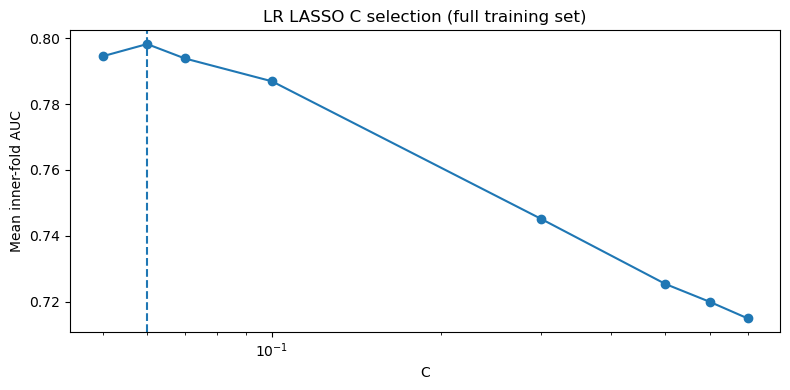

In [7]:
def choose_lasso_c(X, y, seed, progress_label="LR"):
    inner_cv = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=seed
    )
    rows = []

    for c in tqdm(C_VALUES, desc=f"{progress_label} | C search"):
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("lr", LogisticRegression(
                C=c,
                l1_ratio=1.0,
                solver="saga",
                class_weight="balanced",
                max_iter=LASSO_MAX_ITER,
                random_state=seed
            ))
        ])

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            scores = cross_val_score(
                pipe, X, y, cv=inner_cv,
                scoring="roc_auc", n_jobs=1
            )

        rows.append({
            "C": float(c),
            "mean_auc": float(np.mean(scores)),
            "std_auc": float(np.std(scores))
        })

    cv_table = pd.DataFrame(rows)
    chosen = cv_table.sort_values(
        ["mean_auc", "C"],
        ascending=[False, True]
    ).iloc[0]

    return float(chosen["C"]), cv_table


# Same 100-bootstrap stability selection, now with progress
def lasso_stability(X, y, selected_c, seed, progress_label="LR"):
    coefs = []

    for b in tqdm(
        range(N_BOOTSTRAPS_LR),
        desc=f"{progress_label} | Bootstraps",
        unit="bootstrap"
    ):
        Xb, yb = resample(
            X, y,
            replace=True,
            n_samples=len(X),
            random_state=seed + b
        )

        scaler = StandardScaler()
        Xbs = scaler.fit_transform(Xb)

        model = LogisticRegression(
            C=selected_c,
            l1_ratio=1.0,
            solver="saga",
            class_weight="balanced",
            max_iter=LASSO_MAX_ITER,
            random_state=seed + b
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            model.fit(Xbs, yb)

        coefs.append(model.coef_[0].copy())

    coef_arr = np.asarray(coefs)

    table = pd.DataFrame({
        "feature": list(X.columns),
        "coef_mean": coef_arr.mean(axis=0),
        "coef_std": coef_arr.std(axis=0),
        "selection_frequency": (coef_arr != 0).mean(axis=0)
    }).sort_values(
        ["selection_frequency", "feature"],
        ascending=[False, True]
    )

    table["selected"] = table["selection_frequency"] >= PI_THR
    features = table.loc[table["selected"], "feature"].tolist()

    if not features:
        raise RuntimeError("No LR features selected.")

    return features, table


print("=== LOGISTIC REGRESSION | FINAL 530-ROW SELECTION ===")

full_lr_c, lr_c_table = choose_lasso_c(X_lr, y_train, RANDOM_STATE, "LR full training")
full_lr_features, lr_table = lasso_stability(X_lr, y_train, full_lr_c, RANDOM_STATE, "LR full training")

print("Full-training LR C:", full_lr_c,
      "| selected features:", len(full_lr_features))
print(lr_table.head(20).to_string(index=False))

lr_c_table.to_csv(OUT_DIR / "NB3_LR_C_selection.csv", index=False)
pd.DataFrame({"best_c": [full_lr_c]}).to_csv(OUT_DIR / "NB3_LR_best_C.csv", index=False)
lr_table.rename(columns={
    "coef_mean": "LR_coef_mean",
    "coef_std": "LR_coef_std",
    "selection_frequency": "LR_selection_frequency",
    "selected": "LR_selected"
}).to_csv(OUT_DIR / "NB3_LR_feature_selection_summary.csv", index=False)

lr_train[full_lr_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_LR_lasso_train.csv", index_label="orig_index")
lr_test[full_lr_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_LR_lasso_test.csv", index_label="orig_index")

print("\n=== LOGISTIC REGRESSION | FOLD-SPECIFIC SELECTION ===")

for f in fold_records:
    fold_no = f["fold"]
    ix = f["train_idx"]
    label = f"LR fold {fold_no}/{N_FOLDS}"

    print(f"\nStarting {label}")

    c, c_table = choose_lasso_c(
        fold_prepared[fold_no]['LR'].loc[ix].drop(columns=['depressed_flag']), y_train.loc[ix],
        f["seed"], label
    )

    features, table = lasso_stability(
        fold_prepared[fold_no]['LR'].loc[ix].drop(columns=['depressed_flag']), y_train.loc[ix],
        c, f["seed"], label
    )

    f["best_c"] = float(c)
    save_fold("LR", lr_train, f, features)

    c_table.to_csv(
        FOLDS_DIR / f"fold_{fold_no}_LR_C_selection.csv",
        index=False
    )
    table.to_csv(
        FOLDS_DIR / f"fold_{fold_no}_LR_selection_summary.csv",
        index=False
    )

    print(f"Completed fold {fold_no}/{N_FOLDS}: "
          f"LR C={c:.3f}, {len(features)} features")

plt.figure(figsize=(8, 4))
plt.semilogx(
    lr_c_table["C"],
    lr_c_table["mean_auc"],
    marker="o"
)
plt.axvline(full_lr_c, linestyle="--")
plt.title("LR LASSO C selection (full training set)")
plt.xlabel("C")
plt.ylabel("Mean inner-fold AUC")
plt.tight_layout()
plt.savefig(OUT_DIR / "NB3_LASSO_regularization_path.png", dpi=140)
plt.show()

### **Model 2: Random Forest — bootstrapped permutation importance**

As in the original NB3: each selection run internally splits its **own training rows** into bootstrap pool and permutation-validation rows, trains 200-tree depth-8 balanced forests, and measures the decrease in validation AUC after shuffling a predictor 10 times. Categories with a >=60% positive-importance frequency and a positive mean are retained. The selection is repeated **independently** in each outer CV training fold.

In [8]:
def permutation_stability(X, y, algorithm, seed, progress_label=None):
    Xpool, Xperm, ypool, yperm = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=seed
    )

    n_boot = (
        N_BOOTSTRAPS_RF if algorithm == "RF"
        else N_BOOTSTRAPS_ANN
    )
    n_repeat = (
        N_REPEATS_RF if algorithm == "RF"
        else N_REPEATS_ANN
    )

    label = progress_label or algorithm
    imp_rows = []

    for b in tqdm(
        range(n_boot),
        desc=f"{label} | Bootstraps",
        unit="bootstrap"
    ):
        if algorithm == "RF":
            Xb, yb = resample(
                Xpool, ypool,
                replace=True,
                n_samples=len(Xpool),
                random_state=seed + b
            )

            m = RandomForestClassifier(
                n_estimators=200,
                max_depth=8,
                class_weight="balanced",
                random_state=seed + b,
                n_jobs=-1
            )
            m.fit(Xb, yb)

            result = permutation_importance(
                m, Xperm, yperm,
                n_repeats=n_repeat,
                scoring="roc_auc",
                random_state=seed + b,
                n_jobs=1
            )

        elif algorithm == "ANN":
            Xb, yb = balanced_bootstrap(
                Xpool, ypool, seed + b
            )

            scaler = StandardScaler().fit(Xb)

            m = MLPClassifier(
                hidden_layer_sizes=(32, 16),
                activation="relu",
                solver="adam",
                alpha=0.01,
                max_iter=ANN_MAX_ITER,
                random_state=seed + b
            )

            with warnings.catch_warnings():
                warnings.simplefilter(
                    "ignore", ConvergenceWarning
                )
                m.fit(scaler.transform(Xb), yb)

            result = permutation_importance(
                m,
                scaler.transform(Xperm),
                yperm,
                n_repeats=n_repeat,
                scoring="roc_auc",
                random_state=seed + b,
                n_jobs=1
            )

        else:
            raise ValueError("algorithm must be RF or ANN")

        imp_rows.append(result.importances_mean)

    imp = np.asarray(imp_rows)

    table = pd.DataFrame({
        "feature": list(X.columns),
        "importance_mean": imp.mean(axis=0),
        "importance_std": imp.std(axis=0),
        "selection_frequency": (imp > 0).mean(axis=0)
    }).sort_values(
        ["importance_mean", "feature"],
        ascending=[False, True]
    )

    table["selected"] = (
        (table["selection_frequency"] >= PI_THR)
        & (table["importance_mean"] > 0)
    )

    features = table.loc[table["selected"], "feature"].tolist()

    if not features:
        raise RuntimeError(
            f"No {algorithm} features selected."
        )

    return features, table

print("=== RANDOM FOREST | FINAL 530-ROW SELECTION ===")

full_rf_features, rf_table = permutation_stability(
    X_rfann, y_train, "RF", RANDOM_STATE,
    "RF full training"
)

print("Full-training RF selected:", len(full_rf_features))
print(rf_table.head(15).to_string(index=False))

rf_train[full_rf_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_RandomForest_train.csv", index_label="orig_index")
rf_test[full_rf_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_RandomForest_test.csv", index_label="orig_index")

print("\n=== RANDOM FOREST | FOLD-SPECIFIC SELECTION ===")

for f in fold_records:
    fold_no = f["fold"]
    ix = f["train_idx"]

    print(f"\nStarting RF fold {fold_no}/{N_FOLDS}")

    features, table = permutation_stability(
        fold_prepared[fold_no]['RF'].loc[ix].drop(columns=['depressed_flag']),
        y_train.loc[ix],
        "RF",
        f["seed"],
        f"RF fold {fold_no}/{N_FOLDS}"
    )

    save_fold("RF", rf_train, f, features)

    table.to_csv(
        FOLDS_DIR / f"fold_{fold_no}_RF_selection_summary.csv",
        index=False
    )

    print(f"Completed RF fold {fold_no}/{N_FOLDS}: "
          f"{len(features)} features")

=== RANDOM FOREST | FINAL 530-ROW SELECTION ===


RF full training | Bootstraps:   0%|          | 0/30 [00:00<?, ?bootstrap/s]

Full-training RF selected: 68
 feature  importance_mean  importance_std  selection_frequency  selected
     C1I         0.020426        0.010361             1.000000      True
     C1J         0.019324        0.011724             1.000000      True
se_score         0.016549        0.010629             0.900000      True
     C1G         0.010662        0.006560             0.966667      True
     G95         0.010551        0.007468             0.900000      True
     D8G         0.006667        0.003955             0.933333      True
    B31F         0.006137        0.005739             0.900000      True
      C3         0.006000        0.003992             0.933333      True
     G94         0.005806        0.005641             0.833333      True
     D8H         0.004498        0.003660             0.933333      True
     D8F         0.003975        0.004726             0.800000      True
     E14         0.003725        0.004594             0.733333      True
     G88         0.00

RF fold 1/5 | Bootstraps:   0%|          | 0/30 [00:00<?, ?bootstrap/s]

Completed RF fold 1/5: 59 features

Starting RF fold 2/5


RF fold 2/5 | Bootstraps:   0%|          | 0/30 [00:00<?, ?bootstrap/s]

... (3 outputs left out)

RF fold 4/5 | Bootstraps:   0%|          | 0/30 [00:00<?, ?bootstrap/s]

Completed RF fold 4/5: 35 features

Starting RF fold 5/5


RF fold 5/5 | Bootstraps:   0%|          | 0/30 [00:00<?, ?bootstrap/s]

Completed RF fold 5/5: 46 features


### **Model 3: Artificial Neural Network — bootstrapped permutation importance**

Oversample **bootstrap training** cases, fit `StandardScaler` to those cases only, train MLP `(32,16)` with `alpha=0.01`, and measure AUC permutation importance on the internal validation pool. Repeat 30 bootstraps, 10 permutation repeats, and retain >=60% positive with positive mean importance. Repeat independently for each outer training fold.

In [9]:
print("=== ARTIFICIAL NEURAL NETWORK | FINAL 530-ROW SELECTION ===")

full_ann_features, ann_table = permutation_stability(X_rfann, y_train, "ANN", RANDOM_STATE, "ANN full training")

print("Full-training ANN selected:", len(full_ann_features))
print(ann_table.head(15).to_string(index=False))

rf_train[full_ann_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_ANN_train.csv", index_label="orig_index")
rf_test[full_ann_features + ["depressed_flag"]].to_csv(OUT_DIR / "NB3_ANN_test.csv", index_label="orig_index")

print("\n=== ARTIFICIAL NEURAL NETWORK | FOLD-SPECIFIC SELECTION ===")

for f in fold_records:
    fold_no = f["fold"]
    ix = f["train_idx"]

    print(f"\nStarting ANN fold {fold_no}/{N_FOLDS}")

    features, table = permutation_stability(
        fold_prepared[fold_no]['ANN'].loc[ix].drop(columns=['depressed_flag']),
        y_train.loc[ix],
        "ANN",
        f["seed"],
        f"ANN fold {fold_no}/{N_FOLDS}"
    )

    save_fold("ANN", rf_train, f, features)
    table.to_csv(FOLDS_DIR / f"fold_{fold_no}_ANN_selection_summary.csv", index=False)

    print(f"Completed ANN fold {fold_no}/{N_FOLDS}: "
          f"{len(features)} features")

=== ARTIFICIAL NEURAL NETWORK | FINAL 530-ROW SELECTION ===


ANN full training | Bootstraps:   0%|          | 0/30 [00:00<?, ?bootstrap/s]

Full-training ANN selected: 67
 feature  importance_mean  importance_std  selection_frequency  selected
     C1I         0.024032        0.009571             1.000000      True
     D8F         0.014785        0.009004             0.966667      True
     E14         0.014185        0.015121             0.800000      True
     D8G         0.012338        0.008864             0.933333      True
     G95         0.012206        0.008252             1.000000      True
     C1J         0.011852        0.006939             0.933333      True
    B31F         0.011692        0.009324             0.933333      True
      B2         0.009370        0.006567             0.966667      True
se_score         0.009113        0.007295             0.866667      True
     A19         0.008375        0.006949             0.900000      True
     D8I         0.008218        0.007918             0.866667      True
     D51         0.008021        0.005790             0.933333      True
     C1G         0.0

ANN fold 1/5 | Bootstraps:   0%|          | 0/30 [00:00<?, ?bootstrap/s]

Completed ANN fold 1/5: 68 features

Starting ANN fold 2/5


ANN fold 2/5 | Bootstraps:   0%|          | 0/30 [00:00<?, ?bootstrap/s]

... (3 outputs left out)

ANN fold 4/5 | Bootstraps:   0%|          | 0/30 [00:00<?, ?bootstrap/s]

Completed ANN fold 4/5: 70 features

Starting ANN fold 5/5


ANN fold 5/5 | Bootstraps:   0%|          | 0/30 [00:00<?, ?bootstrap/s]

Completed ANN fold 5/5: 52 features


### **Feature-selection comparison and fold manifest for NB4**

In [10]:
rf_ann_summary=pd.DataFrame({'feature':X_rfann.columns})
for model,tab in [('RF',rf_table),('ANN',ann_table)]:
    sub=tab.rename(columns={'importance_mean':model+'_importance_mean',
        'importance_std':model+'_importance_std',
        'selection_frequency':model+'_selection_frequency','selected':model+'_selected'})
    rf_ann_summary=rf_ann_summary.merge(sub[['feature',model+'_importance_mean',
        model+'_importance_std',model+'_selection_frequency',model+'_selected']],on='feature')
rf_ann_summary['n_models_selected']=rf_ann_summary[['RF_selected','ANN_selected']].sum(axis=1)
rf_ann_summary.to_csv(OUT_DIR/'NB3_RFANN_feature_selection_summary.csv',index=False)

manifest={'seed':RANDOM_STATE,'n_folds':N_FOLDS,
    'full_selected_features':{'lr':full_lr_features,'rf':full_rf_features,'ann':full_ann_features},
    'folds':[{'fold':f['fold'],'n_train':f['n_train'],'n_val':f['n_val'],
              'hds_train':f['hds_train'],'hds_val':f['hds_val'],
              'best_c':f['best_c'],'features':f['features'],'files':f['files']} for f in fold_records]}
with open(OUT_DIR/'NB3_foldsafe_manifest.json','w') as fp:json.dump(manifest,fp,indent=2)
counts=pd.DataFrame([{'fold':f['fold'],'LR_C':f['best_c'],
    'LR_features':len(f['features']['lr']),'RF_features':len(f['features']['rf']),
    'ANN_features':len(f['features']['ann'])} for f in fold_records])
counts.to_csv(OUT_DIR/'NB3_foldsafe_selection_counts.csv',index=False)
print('FULL TRAINING selected counts:',{'LR':len(full_lr_features),'RF':len(full_rf_features),'ANN':len(full_ann_features)})
print('FOLD-SPECIFIC counts:')
print(counts.to_string(index=False))
assert all(set(f['features'].keys())=={'lr','rf','ann'} for f in fold_records)
print('Saved manifest and all 15 fold-specific feature data pairs to:',OUT_DIR)

FULL TRAINING selected counts: {'LR': 18, 'RF': 68, 'ANN': 67}
FOLD-SPECIFIC counts:
 fold  LR_C  LR_features  RF_features  ANN_features
    1  0.10           20           59            68
    2  0.05           10           42            68
    3  0.05           12           46            79
    4  0.10           17           35            70
    5  0.05           11           46            52
Saved manifest and all 15 fold-specific feature data pairs to: /home/kathleen/THESIS1/NB_OUTS1_TRAINONLY
